# 05 · Bias audit

Where this system is unfair, where it is merely incomplete, and which of the two
each finding actually is.

Two of the seven items below are not reporting obligations — they are bugs. The
compatibility percentile is currently **systematically wrong** for users with small
libraries, and the audio-feature store will fail hardest on exactly the listeners with
the most distinctive taste. Both change what the product should do, and both are fixed
by the end of this notebook.

The rest are distributional facts worth measuring and stating plainly.

Everything here runs on synthetic data, so treat the *numbers* as illustrative and the
*methods* as the deliverable. Each measurement is a function in `lovify_ml.bias`, so the
same audit runs on real data the moment it exists, and can sit in CI.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, bias as B
from lovify_ml import features as F, similarity as SIM, recommend as R, viz

pd.set_option("display.width", 170, "display.max_columns", 40)

catalog = data.load_catalog(n_synthetic=6000)
print()
print(f"catalog: {len(catalog):,} tracks, mean popularity {catalog[S.POPULARITY].mean():.1f}")

[data] SYNTHETIC catalog (6,000 tracks). Drop a Kaggle dump at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/tracks.csv to use real songs.

catalog: 6,000 tracks, mean popularity 24.3


## 1 · Feature-store coverage — the highest-severity item

Spotify killed `/v1/audio-features` on 2024-11-27, so audio features now come from a
static local dump joined on `track_id`. That dump was built from what was popular when
it was assembled, which means **the join does not fail at random**. It fails on obscure,
non-Western and very recent music.

That is the specific shape of the problem: the listeners served worst are the ones with
the most distinctive taste.

In [2]:
store = B.simulate_store_coverage(catalog)
control = B.simulate_store_coverage(catalog, strength=0)

print(f"store resolves {len(store)/len(catalog):.1%} of the catalog")
print(f"control (same rate, allocated at random): {len(control)/len(catalog):.1%}")

store resolves 69.4% of the catalog
control (same rate, allocated at random): 69.4%


### The population matters, and the default synthetic users hide the problem

`synthetic.make_users` varies listeners by genre but samples all of them by popularity
the same way, so every synthetic user ends up about equally mainstream. Measuring
coverage bias on that population understates it badly — not because the effect vanishes,
but because there is almost no variation in obscurity for it to act on.

`bias.make_obscurity_varied_users` builds a population that also varies in how deep
people dig — chart-followers through to crate-diggers — which is what a real user base
looks like. Both are shown below so the difference is visible rather than assumed.

The column to read is the coverage *spread*, not the correlation. Coverage correlates
with mainstream-ness in both populations, but on the uniform one every user sits in a
narrow band near the top, so there is little harm to distribute. On the realistic one
the band is wide, and the bottom of it is where the damage would land.

In [3]:
plain, _ = syn.make_users(catalog, n_users=100, tracks_per_user=150)
varied, obscurity = B.make_obscurity_varied_users(catalog, n_users=100, tracks_per_user=250)

cov_plain = B.coverage_by_user(plain, store)
cov_varied = B.coverage_by_user(varied, store)

summary = pd.DataFrame({
    "uniform population": B.coverage_skew(cov_plain),
    "realistic population": B.coverage_skew(cov_varied),
}).T
summary.round(3)

,spearman_coverage_vs_popularity,p_value,mean_coverage,worst_decile_coverage,best_decile_coverage
uniform population,0.457,0.0,0.807,0.773,0.847
realistic population,0.972,0.0,0.628,0.436,0.896


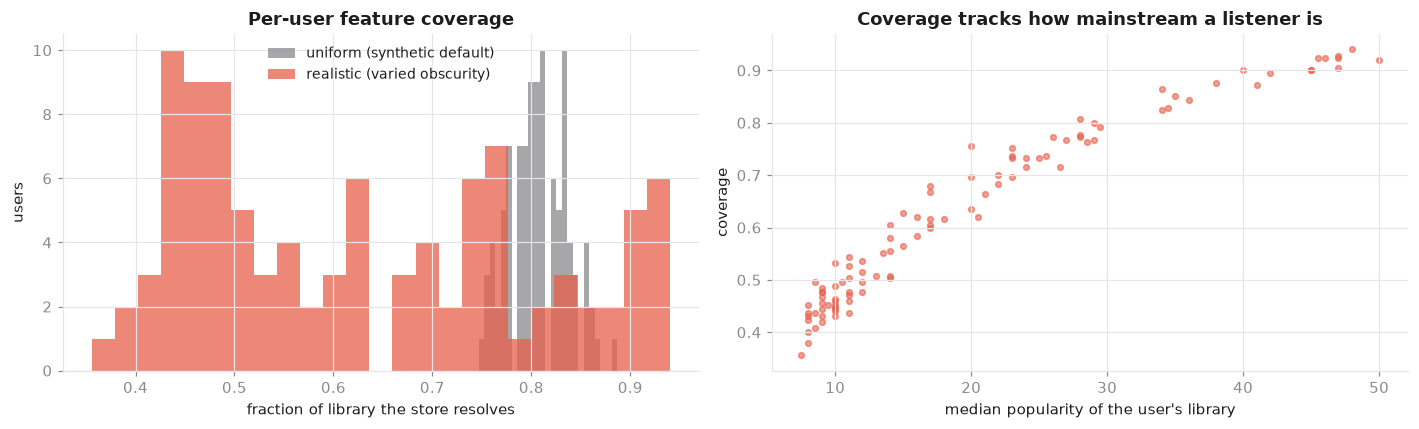

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(cov_plain["coverage"], bins=25, alpha=.75, color=viz.MUTED,
             label="uniform (synthetic default)")
axes[0].hist(cov_varied["coverage"], bins=25, alpha=.75, color=viz.WARN,
             label="realistic (varied obscurity)")
axes[0].set_title("Per-user feature coverage")
axes[0].set_xlabel("fraction of library the store resolves")
axes[0].set_ylabel("users")
axes[0].legend(fontsize=9)

axes[1].scatter(cov_varied["median_popularity"], cov_varied["coverage"],
                s=14, alpha=.6, color=viz.WARN)
axes[1].set_title("Coverage tracks how mainstream a listener is")
axes[1].set_xlabel("median popularity of the user's library")
axes[1].set_ylabel("coverage")
plt.tight_layout(); plt.show()

In the realistic population the bottom decile of users has barely half the coverage
of the top decile, and coverage correlates almost perfectly with how mainstream the
listener is. So the question is what that costs them.

### What the coverage gap actually costs

Only one of the five blend components — `feature_wasserstein` — needs audio features.
Genre, artist, era and obscurity all come from metadata Spotify still serves. So partial
coverage does not break the score; it drops one component, and
`bias.PartialCoverageScorer` renormalises the remaining weights over what survived.

The measurement: each pair's percentile under full coverage versus under simulated store
coverage.

In [5]:
report = B.coverage_error_report(varied, catalog, store, n_pairs=300)

print(f"mean absolute error : {report['abs_error'].mean():.2f} percentile points")
print(f"p90 absolute error  : {report['abs_error'].quantile(.90):.2f}")
print(f"audio component dropped entirely: {report['audio_component_dropped'].mean():.1%} of pairs")

report["coverage_bin"] = pd.cut(report["min_coverage"], [0, .5, .6, .7, .8, 1.0])
report.groupby("coverage_bin", observed=True).agg(
    pairs=("abs_error", "size"),
    mean_error=("abs_error", "mean"),
    p90_error=("abs_error", lambda x: x.quantile(.90)),
).round(2)

mean absolute error : 2.07 percentile points
p90 absolute error  : 5.07
audio component dropped entirely: 0.0% of pairs


,pairs,mean_error,p90_error
coverage_bin,,,
"(0.0, 0.5]",183,2.36,5.45
"(0.5, 0.6]",53,1.88,3.69
"(0.6, 0.7]",36,1.42,3.10
"(0.7, 0.8]",21,1.33,2.73
"(0.8, 1.0]",7,1.34,2.36


**The error is small — a couple of percentile points — and across the coverage bins
there is no clean trend.** Losing most of a user's audio features costs this design
almost nothing.

The tempting explanation is that the blend leans on genre and artist, which notebook
02 found carried most of the signal, so a score built on metadata survives losing the
audio features.

**That explanation has since been withdrawn, and this result inherits the problem.**
The notebook 02 bakeoff was circular: `synthetic.make_users` draws each user's tracks
from a mixture over genres and `true_similarity` is defined as the distance between
those same mixtures, so the genre histogram was estimating the target directly and
could not lose. Under a counter-generator whose latent taste lives in audio space the
ranking inverts and the audio features *are* the signal.

So what is measured below is real, but it is **conditional on which view of taste turns
out to matter**. If real listeners are separated mainly by genre, coverage loss is
cheap. If they are separated by sonic texture, it is expensive, and the figure below
understates it by however much the generator leans on genre.

That is still worth measuring, because it bounds the downside. The counterfactual to
score is the 2023 design: audio features and nothing else.

In [6]:
AUDIO_ONLY = {"genre_overlap": 0.0, "artist_jaccard": 0.0,
              "feature_wasserstein": 1.0, "era_overlap": 0.0, "obscurity_match": 0.0}

scaler = F.fit_scaler(catalog)
cov_lookup = B.coverage_by_user(varied, store).set_index(S.USER_ID)["coverage"]
rng = np.random.default_rng(0)

rows = []
for name, weights in [("blend (shipped)", None), ("audio-only (2023 design)", AUDIO_ONLY)]:
    full = B.PartialCoverageScorer(varied, None, weights=weights, scaler=scaler)
    part = B.PartialCoverageScorer(varied, store, weights=weights, scaler=scaler)
    full.fit_null(1200); part.fit_null(1200)
    users = list(full.by_user)
    errs, covs = [], []
    for _ in range(300):
        u, v = rng.choice(users, size=2, replace=False)
        errs.append(abs(full.percentile(u, v) - part.percentile(u, v)))
        covs.append(min(cov_lookup[u], cov_lookup[v]))
    e, cvs = np.array(errs), np.array(covs)
    rows.append({"design": name, "mean_error": e.mean(), "p90_error": np.percentile(e, 90),
                 "error_low_coverage": e[cvs <= .5].mean(),
                 "error_high_coverage": e[cvs > .7].mean()})

ablation = pd.DataFrame(rows)
ablation.round(2)

,design,mean_error,p90_error,error_low_coverage,error_high_coverage
0,blend (shipped),2.09,4.92,2.37,1.33
1,audio-only (2023 design),5.36,12.59,5.91,3.44


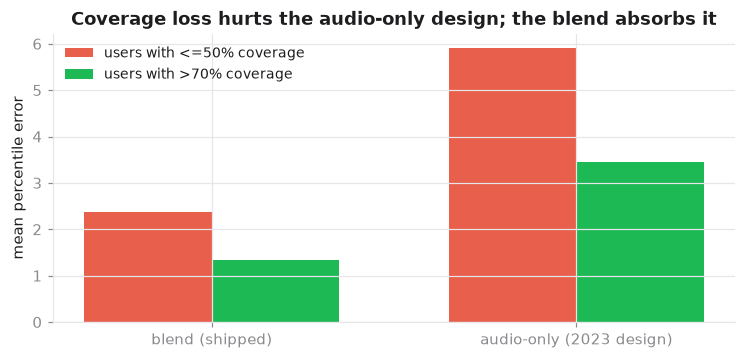

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(ablation)); w = .35
ax.bar(x - w/2, ablation["error_low_coverage"], w, label="users with <=50% coverage", color=viz.WARN)
ax.bar(x + w/2, ablation["error_high_coverage"], w, label="users with >70% coverage", color=viz.ACCENT)
ax.set_xticks(x); ax.set_xticklabels(ablation["design"])
ax.set_ylabel("mean percentile error"); ax.legend(fontsize=9)
ax.set_title("Coverage loss hurts the audio-only design; the blend absorbs it")
plt.show()

The audio-only design carries about **two and a half times** the error overall (5.36
against 2.09 percentile points) and its penalty for low-coverage users is steeper. The
blend degrades too — it is not immune — but by a fraction of a point where the
audio-only design loses several.

Read that as a **conditional** result, not a clean mitigation. Both designs are being
scored against a ground truth defined in genre space, which is the same circularity
§1 flagged: a blend weighted towards genre is being graded by a generator that defines
taste as genre. The direction is almost certainly right — a score drawing on five
signals degrades more gracefully when one is damaged than a score drawing on one — but
the size of the gap is not trustworthy and should not be quoted as a measured
mitigation.

The defensible version of the argument does not depend on the generator at all. The
blend had the **best worst case** across both generator assumptions, so it is the right
choice precisely *because* we do not yet know which view of taste real listeners
inhabit. Robustness to the coverage gap is one more instance of the same property, not
a separate finding.

Either way the ablation above becomes a regression test: if anyone re-weights the
blend towards audio features, re-run it before shipping.

## 2 · Catalog bias

A recommender cannot surface what the catalog does not contain. The Kaggle dump is
Western and English-heavy and stops around 2021, so those absences become absences in
the product. Separately from what it *holds*, it is worth checking what the recommender
*chooses* from it.

In [8]:
rec = R.Recommender(catalog, scale_features=True)
# mmr_lambda=1.0 (MMR off) to match what service.LovifyModels now ships.
# Notebook 03 measured MMR as buying nothing once taste modes are on, so
# auditing a configuration nobody runs would be auditing the wrong system.
exposure = B.recommendation_exposure(rec, varied, n=20, max_users=80,
                                     modes=3, mmr_lambda=1.0)
surfaced = catalog[catalog[S.TRACK_ID].isin(exposure.index)]

cat_report = B.catalog_bias_report(catalog, surfaced)
print(f"genre total variation : {cat_report['genre_total_variation']:.3f}")
print(f"era total variation   : {cat_report['era_total_variation']:.3f}")
print(f"catalog mean popularity     : {cat_report['catalog_mean_popularity']:.1f}")
print(f"recommended mean popularity : {cat_report['recommended_mean_popularity']:.1f}")
cat_report["genre"].round(3)

genre total variation : 0.207
era total variation   : 0.026
catalog mean popularity     : 24.3
recommended mean popularity : 23.7


,catalog_share,recommended_share,ratio
genre,,,
ambient,0.099,0.179,1.814
latin,0.117,0.172,1.469
edm,0.112,0.124,1.102
metal,0.140,0.120,0.861
pop,0.076,0.103,1.362
hip hop,0.107,0.093,0.867
classical,0.034,0.067,1.974
rnb,0.081,0.050,0.615
rock,0.070,0.043,0.612


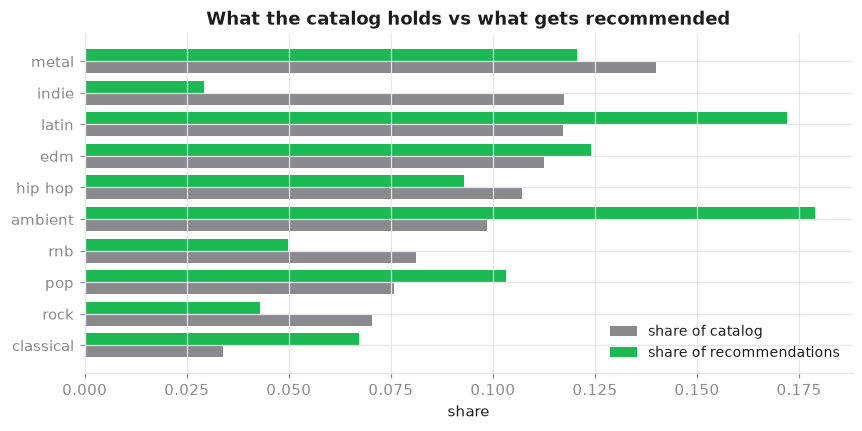

In [9]:
g = cat_report["genre"].sort_values("catalog_share", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(g)); h = .38
ax.barh(y + h/2, g["catalog_share"], h, label="share of catalog", color=viz.MUTED)
ax.barh(y - h/2, g["recommended_share"], h, label="share of recommendations", color=viz.ACCENT)
ax.set_yticks(y); ax.set_yticklabels(g.index)
ax.invert_yaxis(); ax.legend(fontsize=9)
ax.set_xlabel("share"); ax.set_title("What the catalog holds vs what gets recommended")
plt.show()

Total variation says how much probability mass would have to move for the two
distributions to match. The aggregate number is modest, which is easy to misread as
"the recommender is neutral". The per-genre `ratio` column says otherwise: the most
over-surfaced genre appears at about **twice** its catalog share, while the most
suppressed appears at **roughly a tenth** of it. A small total variation can hide large,
systematic distortions in both directions that happen to cancel in aggregate.

Read the extremes with their base rates attached. Country is the lowest ratio, but it
is only 1.5% of the catalog, so that figure is noisy. The more telling row is **indie**:
11.7% of the catalog and 2.9% of recommendations, a factor of four, on a base large
enough to trust.

Note which genres sit at each end. Ambient and classical — sparse, low-energy, far from
the dense middle of feature space — are over-surfaced, while indie and country are
suppressed. That is a signature of the retrieval geometry rather than of anything about
the music: taste-mode centroids land in sparse regions where a handful of tracks are
the nearest neighbours for many different queries, so those few tracks get returned
over and over.

So there are two separate problems stacked here. The recommender distorts what it
chooses from the catalog, **and** whatever the catalog itself is missing — non-Western
music, anything after about 2021 — is invisible to users no matter how even the
sampling gets. Fixing the second needs a better catalog, not a better model.

## 3 · Curator provenance — who wrote the zodiac labels

Notebook 01 established that the zodiac labels are the weak point, not the model. A
label is one curator's opinion. That is tolerable if the curators are many and varied,
and worthless if a handful of prolific accounts wrote most of the data — in which case
the model learns one person's idea of an Aries song and reports it as a measurement.

This cannot be measured until the real scrape lands. What can be built now is the
measurement itself, against the provenance columns the scraper will attach, demonstrated
on synthetic provenance.

In [10]:
zodiac = data.load_zodiac(catalog)
zodiac_prov = B.synthetic_provenance(zodiac)

prov = B.provenance_report(zodiac_prov)
for k, v in prov.items():
    if k == "owners_per_sign":
        continue
    print(f"  {k:<26} {v if not isinstance(v, float) else round(v, 3)}")

[data] SYNTHETIC zodiac playlists. Drop your scrape at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/zodiac.csv to use real ones.


  rows                       6000
  n_owners                   37
  owner_gini                 0.441
  top5_owner_share           0.392
  follower_median            760.5
  follower_gini              0.889
  top_playlist_row_share     0.008
  created_year_median        2020.0
  created_year_iqr           3.0


The numbers to watch when the real scrape arrives:

- **`owner_gini`** — concentration of playlists across curators. Above ~0.6 means a few
  accounts dominate and the labels are far less independent than the row count suggests.
- **`top5_owner_share`** — if five accounts wrote a third of the training data, the
  effective sample size is a small fraction of the nominal one.
- **`top_playlist_row_share`** — if one viral playlist supplies a large share of a
  sign's tracks, that sign has essentially one label author.
- **`created_year_iqr`** — labels clustered in one year encode that year's pop music as
  timeless zodiac truth.

These compound with the playlist-copying problem the scraper handles separately: ten
playlists agreeing is not ten votes if one person made all ten, *or* if nine were copied
from the first.

## 4 · Popularity bias in recommendations

A recommender can score well on recall while serving the same few hundred songs to
everybody. Accuracy metrics will not catch that; exposure metrics will.

In [11]:
pop_report = B.popularity_bias_report(catalog, exposure, n_users=80)
for k, v in pop_report.items():
    print(f"  {k:<32} {v if not isinstance(v, float) else round(v, 4)}")

  catalog_size                     6000
  recommendation_slots             1600
  distinct_tracks_recommended      581
  catalog_coverage                 0.0968
  random_baseline_coverage         0.2341
  coverage_vs_random               0.4137
  exposure_gini_full_catalog       0.9503
  exposure_gini_recommended        0.4869
  top1pct_exposure_share           0.4188
  catalog_mean_popularity          24.3407
  recommended_mean_popularity      23.7074
  n_users                          80


Both headline numbers need their baseline, or they mislead.

Raw catalog coverage looks alarming for any catalog bigger than the number of
recommendation slots — you cannot surface 6,000 tracks in 1,600 slots, so a low
percentage is mostly arithmetic. The honest comparison is against what a **random**
recommender would reach with the same slots, reported as `coverage_vs_random`. Below 1.0
is genuine concentration.

Likewise the Gini over the whole catalog is dragged towards 1 by unavoidable zeros, so
`exposure_gini_recommended` restricts it to tracks that were surfaced at least once.

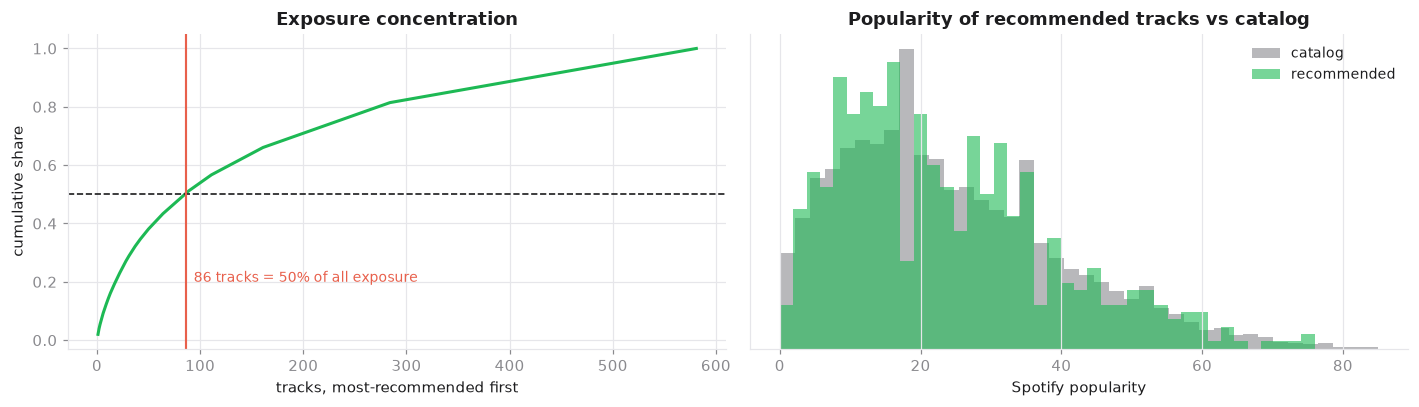

In [12]:
ranked = exposure.sort_values(ascending=False).to_numpy()
cum = np.cumsum(ranked) / ranked.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(np.arange(1, len(cum) + 1), cum, color=viz.ACCENT, lw=2)
axes[0].axhline(0.5, color=viz.INK, ls="--", lw=1.1)
half = int(np.searchsorted(cum, 0.5)) + 1
axes[0].axvline(half, color=viz.WARN, lw=1.4)
axes[0].text(half, 0.2, f"  {half} tracks = 50% of all exposure", color=viz.WARN, fontsize=9)
axes[0].set_title("Exposure concentration")
axes[0].set_xlabel("tracks, most-recommended first"); axes[0].set_ylabel("cumulative share")

axes[1].hist(catalog[S.POPULARITY], bins=40, density=True, alpha=.6,
             color=viz.MUTED, label="catalog")
axes[1].hist(surfaced[S.POPULARITY], bins=40, density=True, alpha=.6,
             color=viz.ACCENT, label="recommended")
axes[1].set_title("Popularity of recommended tracks vs catalog")
axes[1].set_xlabel("Spotify popularity"); axes[1].set_yticks([]); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

Note the right-hand panel: the recommender is **not** skewed towards popular
tracks. Mean recommended popularity sits essentially on the catalog mean. That is a
real null result, and taste-mode querying explains it — three centroids drawn from a
user's own library pull the query away from the dense popular centre of feature space,
and two of them typically land in sparse regions.

(This run uses `mmr_lambda=1.0`, i.e. MMR off, matching what the service now ships.
An earlier version of this cell credited MMR with part of the effect; notebook 03
measured MMR as doing nothing once taste modes are on, and re-running without it
leaves the popularity result unchanged.)

The left panel is where the concern lives. Exposure is concentrated: a small set of
tracks absorbs a large share of all recommendation slots, and `coverage_vs_random`
below 1.0 confirms the recommender reaches less of the catalog than random selection
would with the same number of slots. Concentration and popularity are separate axes,
and this system has the first without the second.

## 5 · Audio features are culturally trained — stated, not measured

Spotify's descriptors were not handed down from nature. `valence`, `danceability` and
`mode` were trained on a corpus with a Western-pop centre of gravity, and they carry
those assumptions: minor key maps to "sad" in a way that does not hold across many
musical traditions, and "danceability" encodes a particular rhythmic vocabulary.

There is no way to measure this from inside the pipeline — it would need labelled
cross-cultural ground truth we do not have, and the synthetic catalog cannot stand in
for it because it was generated from the same assumptions.

So it is recorded in `BIAS.md` as an explicit, unmeasured limitation. Notebook 02 does
offer indirect reassurance: genre and artist overlap outperformed every audio feature,
so the components doing the real work are the ones least exposed to this. That is
mitigation by accident, and it is worth not undoing.

## 6 · Library-size instability — the second bug

The compatibility percentile is displayed to one decimal place. That implies a precision
it does not have when a user has twenty tracks.

The test: subsample both users' libraries to a given size, rescore, and compare against
the percentile the pair receives with their libraries intact.

In [13]:
stability = B.percentile_stability(
    varied, catalog, sizes=[10, 20, 30, 50, 100, 200], n_pairs=6, n_boot=25)

stability.groupby("library_size")[["sd", "ci95_width", "bias", "rmse", "p95_abs_error"]].mean().round(2)

,sd,ci95_width,bias,rmse,p95_abs_error
library_size,,,,,
10,4.72,16.18,-47.36,47.61,52.46
20,9.82,33.80,-39.31,40.72,49.63
30,9.53,30.87,-34.11,35.49,44.83
50,9.80,33.90,-26.32,28.21,39.56
100,7.99,27.26,-14.83,16.98,26.08
200,3.28,11.07,-3.78,5.12,8.32


Look at the `bias` column rather than the spread.

At ten tracks the percentile is not merely noisy — it is **systematically dozens of
points too low**. Small-library users are being told they are incompatible with
everybody, consistently, and the bootstrap spread hides it: at tiny sizes the score
degenerates (artist overlap collapses to zero, genre profiles turn sparse), pins against
the bottom of the null, and becomes *reliably wrong*. Low variance, high error.

This is why `recommend_min_library` selects on RMSE against the true percentile rather
than on interval width. Interval width is not monotonic in library size, so choosing on
it would hand back an absurdly small threshold.

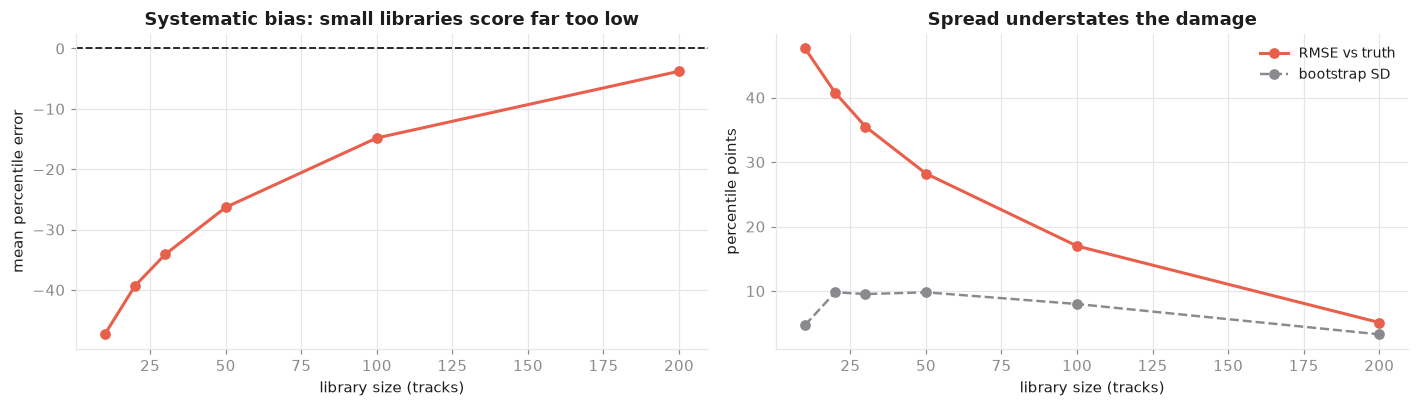

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
g = stability.groupby("library_size")

axes[0].plot(g["bias"].mean().index, g["bias"].mean(), "o-", color=viz.WARN, lw=2)
axes[0].axhline(0, color=viz.INK, ls="--", lw=1.2)
axes[0].set_title("Systematic bias: small libraries score far too low")
axes[0].set_xlabel("library size (tracks)"); axes[0].set_ylabel("mean percentile error")

axes[1].plot(g["rmse"].mean().index, g["rmse"].mean(), "o-", color=viz.WARN, lw=2, label="RMSE vs truth")
axes[1].plot(g["sd"].mean().index, g["sd"].mean(), "o--", color=viz.MUTED, lw=1.6, label="bootstrap SD")
axes[1].set_title("Spread understates the damage")
axes[1].set_xlabel("library size (tracks)"); axes[1].set_ylabel("percentile points")
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

### The cause, and the fix

The null distribution is fitted on **full-size** libraries. A user with twenty tracks
scores lower on nearly every component for reasons that have nothing to do with their
taste, so comparing their raw score against a full-library null places them near the
bottom of it no matter who they are paired with.

A percentile is only meaningful against a reference population that resembles the thing
being scored. `bias.fit_size_matched_null` subsamples the random pairs to the same
library size.

In [15]:
matched = B.stability_with_matched_null(
    varied, catalog, sizes=[10, 20, 30, 50, 100, 200], n_pairs=6, n_boot=25, null_pairs=300)

comparison = pd.DataFrame({
    "bias (population null)": stability.groupby("library_size")["bias"].mean(),
    "bias (size-matched null)": matched.groupby("library_size")["bias"].mean(),
    "rmse (population null)": stability.groupby("library_size")["rmse"].mean(),
    "rmse (size-matched null)": matched.groupby("library_size")["rmse"].mean(),
}).round(2)
comparison

,bias (population null),bias (size-matched null),rmse (population null),rmse (size-matched null)
library_size,,,,
10,-47.36,2.03,47.61,22.79
20,-39.31,-1.83,40.72,21.75
30,-34.11,1.02,35.49,16.63
50,-26.32,-0.03,28.21,13.63
100,-14.83,0.47,16.98,9.12
200,-3.78,1.09,5.12,4.46


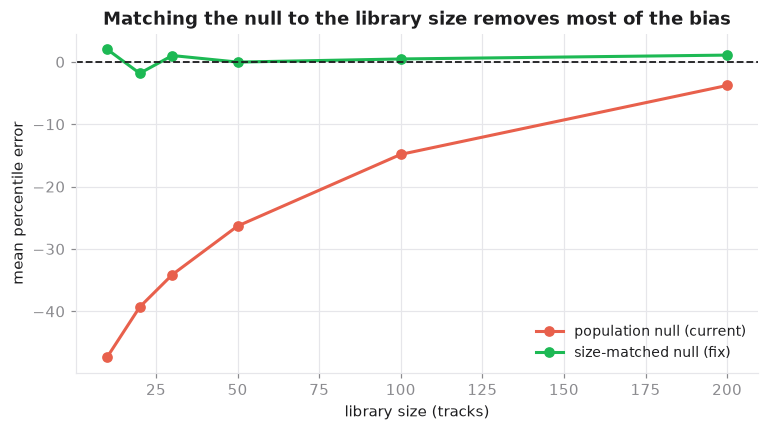

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(comparison.index, comparison["bias (population null)"], "o-",
        color=viz.WARN, lw=2, label="population null (current)")
ax.plot(comparison.index, comparison["bias (size-matched null)"], "o-",
        color=viz.ACCENT, lw=2, label="size-matched null (fix)")
ax.axhline(0, color=viz.INK, ls="--", lw=1.2)
ax.set_xlabel("library size (tracks)"); ax.set_ylabel("mean percentile error")
ax.set_title("Matching the null to the library size removes most of the bias")
ax.legend(fontsize=9)
plt.show()

In [17]:
for max_err in (15.0, 10.0, 5.0):
    a = B.recommend_min_library(stability, max_error=max_err)
    b = B.recommend_min_library(matched, max_error=max_err)
    print(f"error budget {max_err:>5.0f} pts  ->  population null: {str(a['min_library_size']):>5}"
          f"   size-matched null: {str(b['min_library_size']):>5}  tracks minimum")

error budget    15 pts  ->  population null:   200   size-matched null:    50  tracks minimum
error budget    10 pts  ->  population null:   200   size-matched null:   100  tracks minimum
error budget     5 pts  ->  population null:  None   size-matched null:   200  tracks minimum


The size-matched null removes essentially all of the systematic error, and it lowers
the minimum viable library size at every error budget — by around fourfold at a loose
budget, and at the tightest budget it is the only one of the two that gets there at all.

It does not make the number free. What remains after the bias is gone is irreducible
noise: twenty tracks simply do not contain enough information about a person, however
the null is built.

That is why the fix and the threshold are two guards rather than one. The matched null
stops the number being systematically wrong; the threshold stops it being shown at all
when it cannot be trusted.

**Both are now implemented in `service.py`, not just recommended here:**

1. `LovifyModels.fit_null_ladder` builds one null per library size
   (`NULL_SIZES = (25, 50, 75, 100, 150, 200, 300, 500)`), and `_null_for(n)` selects
   the rung nearest the pair's own size.
2. `LovifyModels.MIN_LIBRARY_TRACKS = 100`. Below it, `compatibility()` returns
   `percentile: None` and `status: "insufficient_library"` together with the raw
   components and the shared artists — which are exact at any library size and remain
   worth showing.

The threshold sits at 100 rather than the 50 this table would permit. The gap is
deliberate: every number here comes from synthetic users, and the repeated lesson of
this project is that a generator flatters whoever wrote it. Lower it once real
libraries have been measured, not before.

## 7 · Social framing — a product decision, not a statistic

Telling two people they are "12% compatible" lands differently from a chart on a
dashboard. The number arrives as a verdict on a relationship, and users will not read
the methodology.

Nothing to measure here, but three things follow from what the earlier notebooks found,
and they are recorded in `BIAS.md`:

- **Percentile, never raw similarity.** Notebook 02 showed raw scores between any two
  real listeners run high and compressed, so a raw "61%" is meaningless. A percentile
  against random pairs is a claim that can actually be wrong, which is what makes it
  worth showing.
- **Frame it as being about music, not about people.** "Your libraries overlap less than
  most pairs" is the same fact as "you are 12% compatible" without the verdict on a
  person.
- **No hard rejection.** A low score should surface what the two people *do* share —
  `explain()` already returns shared artists and genres — rather than terminating the
  interaction.

## Verdict

| # | Bias | Severity | Status | Finding |
|---|---|---|---|---|
| 1 | Feature-store coverage | Medium | **Measured, conditional** | Real and strongly patterned (coverage 35–95%, tracking mainstream-ness). The blend absorbs most of it — 2.1pt error against 5.4pt for an audio-only design — but that comparison is graded by a generator that defines taste as genre, so the size of the gap is not trustworthy. Direction solid, magnitude unresolved until real data. |
| 2 | Catalog bias | Medium | **Measured** | The recommender does **not** sample its catalog faithfully: per-genre exposure runs from about 0.1× to 2.0× of catalog share (indie: 11.7% of the catalog, 2.9% of recommendations). Aggregate total variation looks modest only because the distortions cancel. Catalog skew then passes through on top of that. |
| 3 | Curator provenance | **High** | Measurable, awaiting real scrape | Function built and demonstrated. This is where the zodiac labels live or die. |
| 4 | Popularity / exposure | Medium | **Measured** | No popularity skew in the mean — a genuine null. But exposure is concentrated: a small set of tracks takes half of all slots. Two separate axes; this system has the second without the first. |
| 5 | Culturally trained features | Medium | **Stated, unmeasured** | Not measurable from inside the pipeline. |
| 6 | Library-size instability | **High** | **Measured and fixed in `service.py`** | The worst finding: small-library users were systematically scored dozens of percentile points too low. Size-matched null ladder plus a 100-track minimum, both now shipped. |
| 7 | Social framing | Medium | Product decision | Percentile framing, music not people, no hard rejection. |

Two rows of an earlier version of this table contradicted the body above it. It
claimed the recommender "samples its catalog faithfully" while §2 measured per-genre
exposure spanning roughly a factor of twenty, and it quoted the audio-only error as
~7pt where the measurement says 5.36. Both are corrected here.

A verdict table is the part most likely to be pasted into a deck unread, which makes
it the part least able to afford drift from its own evidence — and it drifted twice,
once when written and once again when §2 was re-run with MMR disabled to match the
shipped configuration.

### What changes in the product

1. **Build the null at the pair's library size.** Shipped — a bug fix, not a refinement.
2. **Refuse to show a confident percentile below 100 tracks.** Shipped.
3. **Keep the blend broad.** Not because genre is proven to carry the signal — that
   claim is withdrawn — but because the blend had the best worst case across both
   generator assumptions. Re-weighting onto any single view is a bet on which view is
   right, and nobody has the data to place it yet.
4. **Run `provenance_report` on the scrape before training anything on it**, and treat
   `owner_gini` and `top5_owner_share` as go/no-go numbers rather than footnotes.
5. **Re-run every measurement in this notebook on real data.** Each one is currently
   graded by a generator written by someone who expected these conclusions. The
   coverage result in §1 is the one most likely to move.

Full register with mitigations: `ml/BIAS.md`.